1. JOSE: Data Ingestion & Cleaning: Load your dataset into a Pandas DataFrame. Identify and handle missing values, correct data types, and document your choices.

In [1]:
# Import pandas
import pandas as pd
# Import numpy
import numpy as np
# Import seaborn and matplotlib 
import seaborn as sns
import matplotlib.pyplot as plt

# Set the default style for our graphs
sns.set_theme(style="whitegrid")

# Load the CSV file into a DataFrame called df
df = pd.read_csv("engineering_trends.csv", low_memory=False)

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Show the first five rows to understand the dataset
display(df.head())

Dataset shape: (30903, 212)


,ResponseId,Age,CodeMain,Education,Employment,EmploymentAddl,ICorPM,WorkSetting,LearnCode,LearnCodeHow,...,KnowledgeSourceAI,KnowAgentDelegate,KnowledgeA,TrustReason,KnowAgentTrust,ContextSelect,ContextProblems,ContextFreq,ContextWork,ConvertedCompYearly
0,1,35-44 years old,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",None of the above,Individual contributor in a senior or staff-le...,"Hybrid (some remote, leans heavy to in-person)",Yes,AI codegen tools or AI-enabled apps,...,Important,"Planning, scoping, or estimating work",NaN,I know who created or owns it,The AI tool chooses the information automatically,Current status or ownership,I do not know where to look,Rarely,Manually select files or documents for AI tools,NaN
1,2,45-54 years old,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",Individual contributor,Remote,No,NaN,...,Very important,"Investigating an incident, outage, or producti...",NaN,It comes from an official or trusted source;It...,I do not use AI tools or agents for work,"Code, repositories, or technical documentation...",Different teams have different versions of the...,Often,NaN,NaN
2,3,65 years or older,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Retired,Volunteering (regularly),NaN,NaN,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000.0
3,4,Under 18 years old,I create code as a primary part of my job,Primary/elementary school,Student,Attending school (full-time);Volunteering (reg...,NaN,NaN,Yes,AI codegen tools or AI-enabled apps;Colleague ...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,45-54 years old,I create code as a primary part of my job,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,Individual contributor in a senior or staff-le...,Remote,No,NaN,...,Very important,"Reviewing code, pull requests, or technical ch...",4.0,I know who created or owns it;It includes sour...,I decide exactly what information to give the ...,"Code, repositories, or technical documentation...",Information is incomplete;Information is outda...,Often,Keep notes or prompts in a separate document,85296.0


In [2]:
# Check data type
# Show the data type of every column
print("Data types:")
display(df.dtypes)

# Count how many columns belong to each data type
print("Number of columns by data type:")
display(df.dtypes.value_counts())

# Get basic information about the dataset
df.info()

Data types:


ResponseId               int64
Age                        str
CodeMain                   str
Education                  str
Employment                 str
                        ...   
ContextSelect              str
ContextProblems            str
ContextFreq                str
ContextWork                str
ConvertedCompYearly    float64
Length: 212, dtype: object

Number of columns by data type:


str        197
float64     14
int64        1
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 30903 entries, 0 to 30902
Columns: 212 entries, ResponseId to ConvertedCompYearly
dtypes: float64(14), int64(1), str(197)
memory usage: 50.0 MB


In [3]:
# Missing Values
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values
missing_percent = (df.isnull().mean() * 100).round(2)

# Create a table showing missing values and percentages
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent
})

# Show the 20 columns with the most missing values
display(
    missing_summary.sort_values(
        by="Missing Percentage",
        ascending=False
    ).head(20)
)

# Count columns with more than 50% missing data
print("Columns with more than 50% missing values:",
      (missing_percent > 50).sum())

,Missing Values,Missing Percentage
JobDifficultyAI_9,30903,100.00
JobEaseAI_7,30903,100.00
JobEaseAI_10,30903,100.00
JobEaseAI_9,30903,100.00
JobDifficultyAI_8,30903,100.00
JobDifficultyAI_10,30903,100.00
KnowledgeSource_14,30814,99.71
KnowledgeTime_14,30810,99.70
KnowledgeAcc_14,30805,99.68
AIMemAdmired,30778,99.60


Columns with more than 50% missing values: 179


In [4]:
# Look for duplicates
# Count rows that are exactly identical
print("Duplicate rows:", df.duplicated().sum())

# Check whether the same ResponseId appears more than once
print("Duplicate Response IDs:",
      df["ResponseId"].duplicated().sum())

Duplicate rows: 0
Duplicate Response IDs: 0


In [5]:
# Clean up the dataset
# Create a copy so we do not change the original dataset
clean = df.copy()

# Remove duplicate respondents based on ResponseId
clean = clean.drop_duplicates(subset="ResponseId")

# Identify numerical columns that we want to analyze
numeric_cols = [
    "YearsCode",
    "WorkExp",
    "JobSat",
    "ToolCount",
    "AIToolCount",
    "ConvertedCompYearly"
]

# Convert these columns into numerical values
# Invalid values become NaN (missing values)
for col in numeric_cols:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

# Replace negative experience or compensation with missing values
# These values would not make sense for our analysis
for col in ["YearsCode", "WorkExp", "ConvertedCompYearly"]:
    clean.loc[clean[col] < 0, col] = np.nan

# Check the dataset after cleaning
print("Original dataset:", df.shape)
print("Cleaned dataset:", clean.shape)

# Show missing values in the variables we will analyze
display(clean[numeric_cols].isnull().sum())

Original dataset: (30903, 212)
Cleaned dataset: (30903, 212)


YearsCode               5699
WorkExp                 6296
JobSat                 12027
ToolCount              16067
AIToolCount            18984
ConvertedCompYearly    17396
dtype: int64

Part 1 Findings:
We started by loading the dataset into Pandas and checking its structure. The dataset has 30,903 observations and 212 variables. We checked for missing values, duplicates, and incorrect data types. We decided to keep missing values instead of replacing them with zero because some respondents may not have answered every question. We also converted the numerical variables into the correct format and created a cleaned version of the dataset for our analysis.

2. ALIF: Summary Statistics: Generate descriptive statistics (means, medians, standard deviations, categorical counts) to establish a baseline understanding of the variables.

In [6]:
# Alif: Summary statistics for numerical variables
summary_columns = [
    "YearsCode", "WorkExp", "JobSat",
    "ToolCount", "AIToolCount", "ConvertedCompYearly"
]

summary_values = clean[summary_columns]

# Missing answers are excluded from each variable's calculations.
numeric_summary = pd.DataFrame({
    "Available": summary_values.count(),
    "Missing": summary_values.isna().sum(),
    "Missing (%)": summary_values.isna().mean() * 100,
    "Mean": summary_values.mean(),
    "Median": summary_values.median(),
    "Std. dev.": summary_values.std(ddof=1),
    "Minimum": summary_values.min(),
    "Maximum": summary_values.max()
})

numeric_summary.index.name = "Variable"

# Show two decimal places without changing the underlying values.
with pd.option_context(
    "display.float_format", "{:,.2f}".format,
    "display.max_columns", None
):
    display(numeric_summary)

,Available,Missing,Missing (%),Mean,Median,Std. dev.,Minimum,Maximum
Variable,,,,,,,,
YearsCode,25204,5699,18.44,17.33,15.00,12.03,1.00,100.00
WorkExp,24607,6296,20.37,14.26,12.00,11.73,1.00,100.00
JobSat,18876,12027,38.92,6.96,7.00,2.15,0.00,10.00
ToolCount,14836,16067,51.99,34.87,6.00,478.94,0.00,"10,000.00"
AIToolCount,11919,18984,61.43,"92,307,864,391.81",2.00,"9,205,283,519,134.44",0.00,"999,999,999,999,999.00"
ConvertedCompYearly,13507,17396,56.29,"106,535.07","79,610.00","445,367.66",1.00,"31,919,350.00"


In [10]:
# Alif: Summary statistics for categorical variables
category_columns = [
    "Education", "Employment", "WorkSetting", "Country", "Role"
]
category_values = clean[category_columns]

# Show how many respondents answered each question.
category_coverage = pd.DataFrame({
    "Answered": category_values.notna().sum(),
    "Missing": category_values.isna().sum(),
    "Missing (%)": (category_values.isna().mean() * 100).round(2),
    "Distinct reported categories": category_values.nunique()
})
category_coverage.index.name = "Variable"
display(category_coverage)

category_tables = {}

for column in category_columns:
    # Include missing answers as a separate row.
    counts = clean[column].value_counts()
    counts.loc["Missing / not answered"] = clean[column].isna().sum()

    table = pd.DataFrame({
        "Count": counts,
        "Percent of all respondents (%)": (
            counts / len(clean) * 100
        ).round(2)
    })
    table.index.name = column
    category_tables[column] = table

    # Show the top 10 countries and roles, combining the rest.
    if column in ["Country", "Role"]:
        reported_counts = counts.drop("Missing / not answered")
        shown_counts = reported_counts.head(10).copy()
        shown_counts.loc["All remaining reported categories (combined)"] = (
            reported_counts.iloc[10:].sum()
        )
        shown_counts.loc["Missing / not answered"] = (
            counts.loc["Missing / not answered"]
        )

        table = pd.DataFrame({
            "Count": shown_counts,
            "Percent of all respondents (%)": (
                shown_counts / len(clean) * 100
            ).round(2)
        })
        table.index.name = column

    print(f"\n{column}: counts and percentages of all respondents")
    with pd.option_context(
        "display.max_colwidth", None,
        "display.max_rows", None
    ):
        display(table)

,Answered,Missing,Missing (%),Distinct reported categories
Variable,,,,
Education,30761,142,0.46,8
Employment,30903,0,0.00,6
WorkSetting,24602,6301,20.39,5
Country,21370,9533,30.85,169
Role,25767,5136,16.62,41



Education: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Education,,
"Bachelor's degree (B.A., B.S., B.Eng., etc.)",12396,40.11
"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",7990,25.86
Some college/university study without earning a degree,3813,12.34
"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",2431,7.87
"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",1812,5.86
"Associate degree (A.A., A.S., etc.)",942,3.05
Primary/elementary school,706,2.28
"Other, please specify",671,2.17
Missing / not answered,142,0.46



Employment: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Employment,,
Employed,20259,65.56
"Independent contractor, freelancer, or self-employed",4607,14.91
Student,3139,10.16
Not employed,1742,5.64
Retired,607,1.96
I prefer not to say,549,1.78
Missing / not answered,0,0.00


...

,Count,Percent of all respondents (%)
WorkSetting,,
Remote,8564,27.71
"Hybrid (some remote, leans heavy to in-person)",4883,15.80
In-person,4335,14.03
"Hybrid (some in-person, leans heavy to flexibility)",3823,12.37
"Your choice (very flexible, you can come in when you want or just as needed)",2997,9.70
Missing / not answered,6301,20.39



Country: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Country,,
United States of America,4755,15.39
Germany,1983,6.42
United Kingdom of Great Britain and Northern Ireland,1374,4.45
India,1309,4.24
Canada,851,2.75
France,794,2.57
Netherlands,577,1.87
Poland,527,1.71
Australia,522,1.69



Role: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Role,,
"Developer, full-stack",7042,22.79
"Developer, back-end",3473,11.24
Student,1823,5.90
"Architect, software or solutions",1792,5.80
"Developer, desktop or enterprise applications",1030,3.33
"Developer, front-end",933,3.02
"Developer, embedded applications or devices",731,2.37
Academic researcher,705,2.28
"Developer, mobile",685,2.22


In [11]:
# Alif: Count respondents who reported using each language.
language_answers = clean["LanguagesHaveWorkedWith"].dropna()

# "Python;SQL" contributes once to Python and once to SQL.
language_indicators = language_answers.str.get_dummies(sep=";")
language_counts = language_indicators.sum().sort_values(ascending=False)

language_summary = pd.DataFrame({
    "Respondents": language_counts,
    "Percent of language-question respondents (%)": (
        language_counts / len(language_answers) * 100
    ).round(2)
})
language_summary.index.name = "Language / technology"

print(f"Answered the language question: {len(language_answers):,}")
print(
    f"Missing language answers: "
    f"{clean['LanguagesHaveWorkedWith'].isna().sum():,}"
)
print("Percentages use respondents who answered the language question.")
print("A respondent can select multiple languages, so percentages can exceed 100% in total.")

with pd.option_context("display.max_rows", None):
    display(language_summary)

Answered the language question: 13,924
Missing language answers: 16,979
Percentages use respondents who answered the language question.
A respondent can select multiple languages, so percentages can exceed 100% in total.


,Respondents,Percent of language-question respondents (%)
Language / technology,,
JavaScript,8742,62.78
SQL,8237,59.16
HTML/CSS,8211,58.97
Python,8182,58.76
Bash/Shell (all shells),7231,51.93
TypeScript,6169,44.30
Java,3884,27.89
C#,3818,27.42
PowerShell,3472,24.94


### Part 2 findings: Summary statistics

**Approach:** I used the cleaned dataset from Part 1, containing 30,903 respondents. This includes students and retired respondents as well as people currently working. Numerical calculations exclude missing answers separately for each variable, and standard deviations use the sample formula (`ddof=1`). Missing values remain missing rather than being replaced with zero. Compensation uses `ConvertedCompYearly`, following Part 3's USD convention.

**Numerical results:**

- Years of coding have a mean of 17.33 and a median of 15. Professional work experience has a mean of 14.26 years, a median of 12 years, and a standard deviation of 11.73 years.
- Converted annual compensation has a mean of 106,535.07 USD, a median of 79,610 USD, and a standard deviation of 445,367.66 USD. These statistics use 13,507 available responses. Compensation is missing for 17,396 respondents (56.29%), so the results describe only those with available compensation.
- The maximum compensation is 31,919,350 USD. Very large values affect the mean and standard deviation; the median is less sensitive to these extreme values.
- Job satisfaction has a mean of 6.96 and a median of 7. The median tool count is 6, and the median AI-tool count is 2.
- Some values need further checking: both experience variables reach 100 years, tool count reaches 10,000, and AI-tool count reaches 999,999,999,999,999. I retained these values in the baseline summary and flagged them rather than choosing an unsupported cutoff. In particular, the AI-tool mean should not be interpreted as typical tool use.

**Categorical results:**

The percentages in these tables use all 30,903 respondents, including missing answers. A bachelor's degree is the most frequently reported education level (12,396 respondents; 40.11%). The "Employed" category contains 20,259 respondents (65.56%). Remote is the most frequently reported work setting (8,564 respondents; 27.71%). Country and role displays show the top ten categories, the remaining categories combined, and missing answers; complete tables are stored in `category_tables`.

**Language results:**

The language question has 13,924 responses and 16,979 missing answers (54.94%). JavaScript is the most frequently selected option (8,742 respondents; 62.78% of those who answered). Python was selected by 8,182 respondents (58.76%). Each language is counted at most once per respondent. Since respondents can select several languages, the percentages can total more than 100%.

These summaries describe the survey respondents and provide a starting point for later analysis. They do not establish that learning a particular language causes higher pay. Later salary comparisons should consider experience, country, employment status, missing answers, and questionable extreme values.

**Contribution — Alif:** Numerical summary statistics, categorical and language counts, missing-response summaries, and interpretation of the results.

3. JOSE: Initial Visualizations: Create foundational plots (e.g., histograms, scatter plots, box plots using Seaborn) to identify distributions, outliers, and potential correlations.

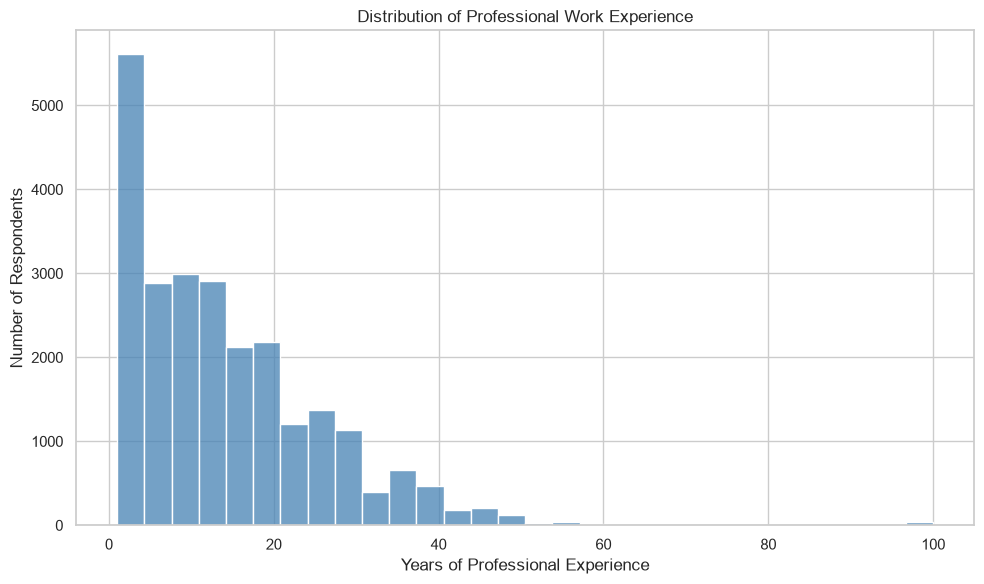

In [7]:
# Create the figure and set its size
plt.figure(figsize=(10, 6))

# Create a histogram showing years of professional experience
sns.histplot(
    data=clean,
    x="WorkExp",
    bins=30,              # Divide experience into 30 intervals
    color="steelblue",    # Set the bar color
    edgecolor="white"     # Add white borders between bars
)

# Add a descriptive title
plt.title("Distribution of Professional Work Experience")

# Label the horizontal axis
plt.xlabel("Years of Professional Experience")

# Label the vertical axis
plt.ylabel("Number of Respondents")

# Adjust spacing so labels are not cut off
plt.tight_layout()

# Display the graph
plt.show()

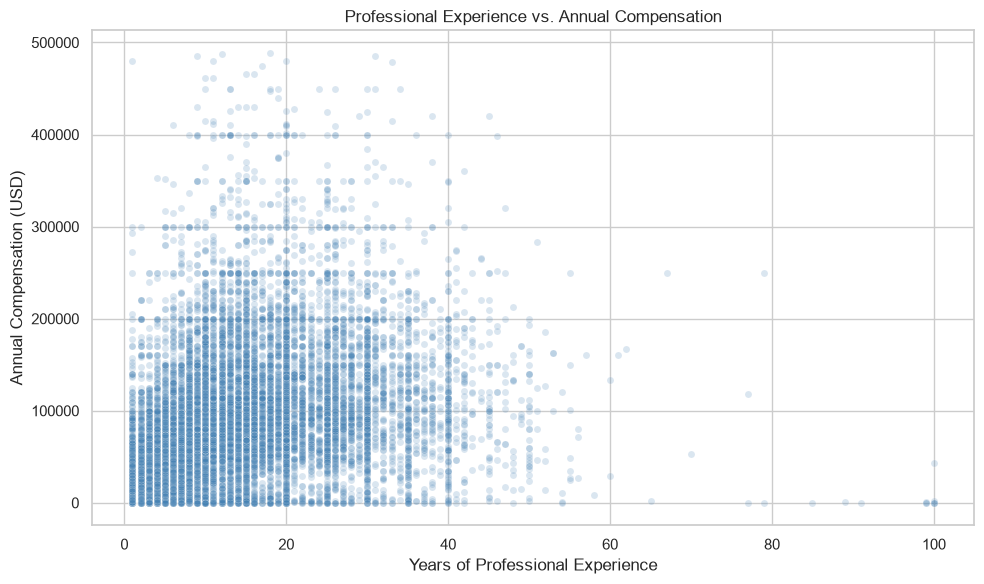

In [8]:
# Keep respondents who reported both experience and compensation
salary_data = clean.dropna(
    subset=["WorkExp", "ConvertedCompYearly"]
).copy()

# Keep only positive compensation values
salary_data = salary_data[
    salary_data["ConvertedCompYearly"] > 0
]

# Find the 99th percentile of compensation
# This helps limit the influence of extremely high salaries on the graph
salary_limit = salary_data["ConvertedCompYearly"].quantile(0.99)

# Create a dataset for plotting without the top 1% of salaries
salary_plot = salary_data[
    salary_data["ConvertedCompYearly"] <= salary_limit
].copy()

# Set the graph size
plt.figure(figsize=(10, 6))

# Create a scatter plot comparing experience and compensation
sns.scatterplot(
    data=salary_plot,
    x="WorkExp",
    y="ConvertedCompYearly",
    alpha=0.2,           # Make points transparent to see overlapping values
    color="steelblue",
    s=25                 # Set the size of each point
)

# Add a title and axis labels
plt.title("Professional Experience vs. Annual Compensation")
plt.xlabel("Years of Professional Experience")
plt.ylabel("Annual Compensation (USD)")

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()

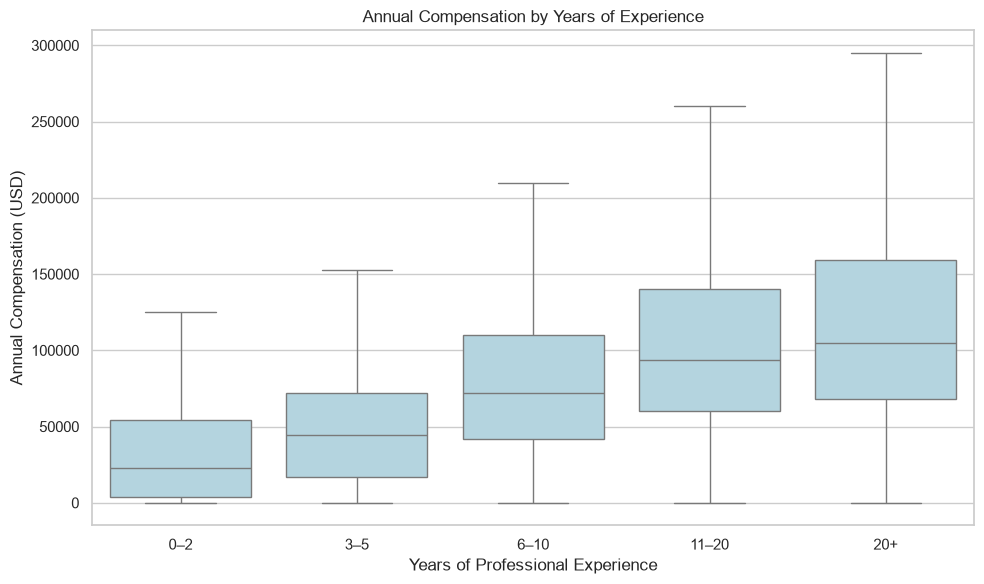

In [9]:
# Create a copy of the salary dataset for this graph
experience_data = salary_plot.copy()

# Divide respondents into five experience groups
experience_data["Experience Group"] = pd.cut(
    experience_data["WorkExp"],
    bins=[-0.01, 2, 5, 10, 20, np.inf],
    labels=["0–2", "3–5", "6–10", "11–20", "20+"]
)

# Set the graph size
plt.figure(figsize=(10, 6))

# Create a box plot comparing compensation across experience groups
sns.boxplot(
    data=experience_data,
    x="Experience Group",
    y="ConvertedCompYearly",
    color="lightblue",
    showfliers=False     # Hide outlier dots to make the graph easier to read
)

# Add the title and axis labels
plt.title("Annual Compensation by Years of Experience")
plt.xlabel("Years of Professional Experience")
plt.ylabel("Annual Compensation (USD)")

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()

4. SEDAN: Dataset Quirks: Document initial observations, inherent biases in the data collection, and any assumptions you will need to make moving forward.

Part 4 findings: Dataset quirks, biases, and assumptions
Quirks

Over half of salary data is missing. Only 13,507 of 30,903 respondents (43.7%) reported a salary, and response rates differ by group (53% of employed respondents vs. 12% of students).
Salary has implausible values. 521 answers are 1,000 or less and 26 are above 1,000,000 (maximum about $31.9 million), so medians are more reliable than means.
Pay is converted to USD from many currencies with no cost-of-living adjustment, and it varies hugely by country (median about 
17,000 in India).
Experience and tool counts contain impossible values (up to 100 years of experience, 10,000 tools).
The sample includes students, retirees, under-18s, and occasional coders. 179 of 212 columns are more than half empty, and languages are stored as semicolon-separated text

Biases

It is a voluntary online survey, not a random sample of developers. The US makes up 15.4% of respondents, and 86% of those who gave a gender are men.
Salaries are self-reported and unverified, and people who skipped the question may earn differently from those who answered.
Each person answered once, so the data can show association but cannot show that learning a language raises pay.

Assumptions going forward

We will focus on working developers (employed or self-employed, coding as a primary part of the job): 20,220 respondents, 10,561 with a salary.
We will use ConvertedCompYearly with a documented outlier rule, and use medians or log pay.
We will compare pay within a country or control for country, not mix countries.
We will not fill in missing values, and we will report sample sizes.
We will describe results as associations, not cause and effect.